# Vogel oder Park: Kreuzvalidierung

Das erste Notebook hatte 39 von 40 richtig. Bei 40 Bildern verschiebt ein einziges Bild die Trefferquote um 2,5 Prozentpunkte, und welche 40 Bilder es waren, hat der Zufallszahlengenerator entschieden. Wie viel ist die Zahl also wert?

In drei Schritten:

1. Dieselbe Rechnung mit anderen Splits
2. Kreuzvalidierung: jedes Bild einmal in der Validierung
3. Varianten vergleichen

## Merkmale einmal berechnen

Das vortrainierte Modell bleibt eingefroren, sein Ergebnis für ein Bild ändert sich also nie. Wir berechnen die 512 Merkmale jedes Bildes einmal und trainieren danach nur noch die letzte Schicht. Darum kostet jeder der vielen Läufe unten nur Bruchteile einer Sekunde.

In [ ]:
# Nur in Colab: Hilfsdateien und Daten aus dem Repo holen. Lokal tut die Zelle nichts.
import os
import subprocess
import sys

if "google.colab" in sys.modules:
    repo = "/content/ki-workshop-handson"
    if not os.path.exists(repo):
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/dprinz/ki-workshop-handson.git", repo], check=True)
    os.chdir(f"{repo}/birds")

In [1]:
import time

import numpy as np
import torch
from sklearn.model_selection import StratifiedKFold, train_test_split
from torch import nn
from torch.utils.data import DataLoader
from torchvision.datasets import ImageFolder
from torchvision.models import ResNet18_Weights, resnet18

from helfer import zeige_bilder

gewichte = ResNet18_Weights.DEFAULT
bilder = ImageFolder("daten", transform=gewichte.transforms())
geraet = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"

rumpf = resnet18(weights=gewichte)
rumpf.fc = nn.Identity()
rumpf = rumpf.to(geraet).eval()

start = time.perf_counter()
with torch.no_grad():
    merkmale = torch.cat([rumpf(eingabe.to(geraet)).cpu() for eingabe, _ in DataLoader(bilder, batch_size=32)])
label = torch.tensor(bilder.targets)
print(f"{merkmale.shape[0]} Bilder, je {merkmale.shape[1]} Merkmale, {time.perf_counter() - start:.1f} Sekunden")

200 Bilder, je 512 Merkmale, 1.7 Sekunden


In [2]:
def trainiere_und_pruefe(idx_training, idx_validierung, epochen=3, seed=42):
    """Trainiert die letzte Schicht und gibt die Fehlentscheide in der Validierung zurück."""
    torch.manual_seed(seed)
    schicht = nn.Linear(512, 2)
    optimierer = torch.optim.Adam(schicht.parameters(), lr=0.001)
    idx_training = torch.as_tensor(np.array(idx_training))
    for epoche in range(epochen):
        for stapel in idx_training[torch.randperm(len(idx_training))].split(16):
            loss = nn.functional.cross_entropy(schicht(merkmale[stapel]), label[stapel])
            optimierer.zero_grad()
            loss.backward()
            optimierer.step()
    idx_validierung = torch.as_tensor(np.array(idx_validierung))
    with torch.no_grad():
        falsch = schicht(merkmale[idx_validierung]).argmax(1) != label[idx_validierung]
    return idx_validierung[falsch].tolist()

## 1. Dieselbe Rechnung mit anderen Splits

Das Notebook von vorhin, nur der Seed des Splits ändert sich. Hundert Mal 160 Bilder zum Trainieren, 40 zum Prüfen.

In [3]:
treffer = []
for seed in range(100):
    idx_t, idx_v = train_test_split(range(len(label)), test_size=0.2, stratify=bilder.targets, random_state=seed)
    treffer.append(40 - len(trainiere_und_pruefe(idx_t, idx_v)))

werte, anzahl = np.unique(treffer, return_counts=True)
for wert, n in zip(werte, anzahl):
    print(f"{wert} von 40 richtig ({wert / 40:.1%}): {'█' * int(n)} {n}")

38 von 40 richtig (95.0%): ██████ 6
39 von 40 richtig (97.5%): ███████████████████████████████████ 35
40 von 40 richtig (100.0%): ███████████████████████████████████████████████████████████ 59


Derselbe Ablauf ergibt je nach Split 38, 39 oder 40 von 40, also 95 bis 100 %. Die 39 aus dem ersten Notebook ist ein normaler Wert. Genauer als dieser Bereich ist die einzelne Zahl aber nicht, und mit etwas anderem Glück hätte dort 100 % gestanden.

## 2. Kreuzvalidierung: jedes Bild einmal in der Validierung

Wir teilen die 200 Bilder in fünf gleich grosse Teile. Fünfmal dient ein Teil als Validierung, die anderen vier als Training. So war am Ende jedes Bild genau einmal in der Validierung, und jedes Mal hat es ein Modell beurteilt, das es nicht gesehen hatte.

In [4]:
falte = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

alle_falschen = []
for nummer, (idx_t, idx_v) in enumerate(falte.split(merkmale, label), start=1):
    falsch = trainiere_und_pruefe(idx_t, idx_v)
    alle_falschen += falsch
    print(f"Teil {nummer}: {40 - len(falsch)} von 40 richtig")

print(f"\nInsgesamt {200 - len(alle_falschen)} von 200 richtig, {1 - len(alle_falschen) / 200:.1%}")

Teil 1: 40 von 40 richtig
Teil 2: 40 von 40 richtig
Teil 3: 39 von 40 richtig
Teil 4: 40 von 40 richtig
Teil 5: 39 von 40 richtig

Insgesamt 198 von 200 richtig, 99.0%


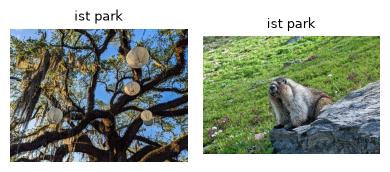

In [5]:
pfade = [bilder.samples[i][0] for i in alle_falschen]
wahr = [bilder.classes[bilder.targets[i]] for i in alle_falschen]
zeige_bilder(pfade, [f"ist {w}" for w in wahr], spalten=min(6, max(len(pfade), 1)))

Beide Fehler sind Parks, die das Modell für Vögel hält: ein Baum mit hellen Kugeln in den Ästen und ein Murmeltier auf einem Felsen. Das Murmeltier zeigt eine Schwäche der Daten: ein Tier in Nahaufnahme mit dem Label Park.

Die 99 % sind ein stabilerer Wert als eine einzelne Validierung, weil 200 statt 40 Bilder zählen. Sie gehören aber nicht zu einem bestimmten Modell. Sie schätzen, wie gut das Verfahren auf 160 Bildern lernt.

## 3. Varianten vergleichen

Im Alltag braucht man Kreuzvalidierung selten für eine einzelne Zahl, sondern zum Vergleichen: Welche Einstellung ist besser, und ist der Unterschied grösser als das Rauschen? Hier die Zahl der Epochen, die im ersten Notebook einfach auf drei stand.

In [6]:
def kreuzvalidiere(epochen):
    return sum(len(trainiere_und_pruefe(t, v, epochen)) for t, v in falte.split(merkmale, label))


for epochen in (1, 3, 10, 30):
    print(f"{epochen:>2} Epochen: {200 - kreuzvalidiere(epochen)} von 200 richtig")

 1 Epochen: 195 von 200 richtig
 3 Epochen: 198 von 200 richtig


10 Epochen: 198 von 200 richtig


30 Epochen: 197 von 200 richtig


Eine Epoche ist mit 195 etwas schlechter, ab drei Epochen liegen die Werte bei 197 bis 198. Ein Unterschied von einem Bild spricht für keine der Einstellungen, also bleiben wir bei der einfachsten.

Vorsicht beim Melden: Wer auf denselben 200 Bildern die beste Variante wählt und deren Zahl nennt, misst zu optimistisch. Für die Schlussmessung braucht es ein Testset, das an der Auswahl nicht beteiligt war, wie bei den drei Datentöpfen im Grundlagenblock.